# 回归：直线、平方曲线与保存加载

线性回归 → 多层网络拟合 x² → 保存并加载平方模型。


In [54]:
from random import uniform

from qutai import nn, visualization

## 1. 线性回归：学习 y = 2x₁ − 3x₂ + 0.5

先生成 64 个样本。每个输入有两个数字，目标是一个数字，所以形状分别是 `(64, 2)` 和 `(64, 1)`。

In [55]:
inputs = [[uniform(-1, 1), uniform(-1, 1)] for _ in range(64)]
targets = [[2 * a - 3 * b + 0.5] for a, b in inputs]

for sample, target in zip(inputs[:3], targets[:3]):
    print("输入:", sample, "目标:", target)

输入: [0.563974489265114, 0.41863858096582773] 目标: [0.3720332356327447]
输入: [-0.20779018341556554, 0.8736939783581126] 目标: [-2.536662301905469]
输入: [0.8197837210654686, 0.7170123572009444] 目标: [-0.011469629471895892]


### 创建模型

一个 Linear 层就能表达这个关系。把它放进 Model，训练和保存都通过同一个模型对象完成。

用 `nn.MSE()` 创建均方误差对象，之后调用 `loss_function(prediction, targets)` 计算损失。

In [56]:
model = nn.Model([
    nn.Linear(2, 1)
])
optimizer = nn.SGD(model, learning_rate=0.1)
loss_function = nn.MSE()

print("训练前 MSE:", loss_function(model(inputs, train=False), targets).item())

训练前 MSE: 3.5303519932762377


### 训练 301 步

每一步都执行：清除旧梯度 → 预测并计算损失 → 反向传播 → 更新参数。

In [57]:
for step in range(301):
    optimizer.zero_grad()
    loss = loss_function(model(inputs), targets)
    loss.backward()
    optimizer.step()

    if step % 50 == 0: print(f"step {step:3d}  loss {loss.item():.8e}")

step   0  loss 3.53035199e+00
step  50  loss 2.83637155e-02
step 100  loss 2.46522589e-04
step 150  loss 2.16128505e-06
step 200  loss 1.89671384e-08
step 250  loss 1.66472109e-10
step 300  loss 1.46112333e-12


### 检查学到的关系

权重应接近 `[[2], [-3]]`，偏置应接近 `0.5`。再用几个新输入对照真实公式。

In [58]:
print("训练后 MSE:", loss_function(model(inputs, train=False), targets).item())
weight, bias = model.parameters()
print("权重:", weight.tolist())
print("偏置:", bias.item())

samples = [[1, 2], [-1, 0], [0.3, -0.4]]
predictions = model(samples, train=False).tolist()
for sample, [prediction] in zip(samples, predictions):
    print(f"输入: {sample}  预测: {prediction:.6f}  目标: {2 * sample[0] - 3 * sample[1] + 0.5:.6f}")

训练后 MSE: 1.3290881779788217e-12
权重: [[1.9999984867050355], [-2.999998142463313]]
偏置: 0.49999991872002103
输入: [1, 2]  预测: -3.499998  目标: -3.500000
输入: [-1, 0]  预测: -1.499999  目标: -1.500000
输入: [0.3, -0.4]  预测: 2.299999  目标: 2.300000


### 画出预测与目标

线性模型有两个输入。固定第二个输入 `x₂=0.25`，只改变 `x₁`，把真实公式与模型预测画在同一坐标系中。


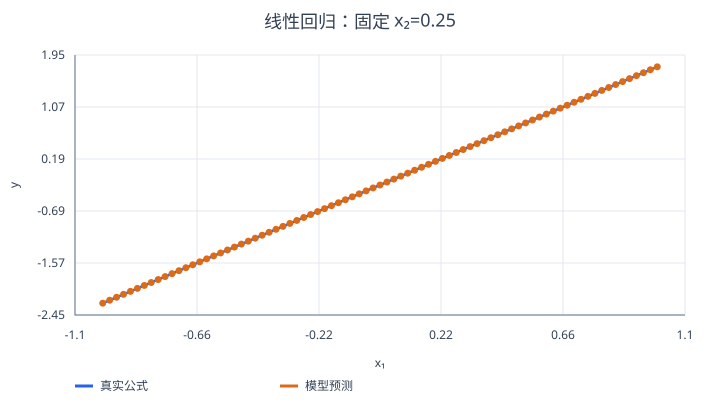

In [60]:
xs = [-1 + 2 * i / 80 for i in range(81)]
y_target = [2 * x - 3 * 0.25 + 0.5 for x in xs]
y_predicted = [row[0] for row in model([[x, 0.25] for x in xs], train=False).tolist()]
visualization.Plot(title="线性回归：固定 x₂=0.25", xlabel="x₁", ylabel="y").line(xs, y_target, label="真实公式").scatter(xs, y_predicted, label="模型预测")

## 2. 多层网络：学习 y = x²

在 `[-1, 1]` 上生成 65 个点。输入和目标形状都是 `(65, 1)`。

In [61]:
inputs = [[-1 + 2 * i / 64] for i in range(65)]
targets = [[x * x] for [x] in inputs]

for sample, target in zip(inputs[:3], targets[:3]):
    print("输入:", sample, "目标:", target)

输入: [-1.0] 目标: [1.0]
输入: [-0.96875] 目标: [0.9384765625]
输入: [-0.9375] 目标: [0.87890625]


### 创建模型

结构为 `Linear(1, 16) → ReLU → Linear(16, 1)`。ReLU 让网络能组合出分段直线，逐渐逼近平滑的平方曲线。

In [62]:
model = nn.Model([
    nn.Linear(1, 16, seed=42),
    nn.ReLU(),
    nn.Linear(16, 1, seed=43),
])
optimizer = nn.SGD(model, learning_rate=0.1)
loss_function = nn.MSE()

print("训练前 MSE:", loss_function(model(inputs, train=False), targets).item())

训练前 MSE: 0.21710499255298835


### 训练 1001 步

训练循环与线性回归相同，只换了模型和数据。

In [63]:
for step in range(1001):
    optimizer.zero_grad()
    loss = loss_function(model(inputs), targets)
    loss.backward()
    optimizer.step()

    if step % 200 == 0: print(f"step {step:4d}  loss {loss.item():.8e}")

step    0  loss 2.17104993e-01
step  200  loss 5.74015559e-03
step  400  loss 4.32356944e-03
step  600  loss 2.58644264e-03
step  800  loss 1.48009727e-03
step 1000  loss 9.36861886e-04


### 检查预测

用随机数生成 64 个新输入检查误差，再打印几个点的预测。`train=False` 暂停记录计算图。

In [64]:
test_inputs = [[uniform(-1, 1)] for _ in range(64)]
test_targets = [[x * x] for [x] in test_inputs]
test_error = loss_function(model(test_inputs, train=False), test_targets).item()
print("训练后 MSE:", loss_function(model(inputs, train=False), targets).item())
print(f"独立测试 MSE: {test_error:.8e}")

samples = [[-0.9], [-0.45], [0], [0.35], [0.8]]
predictions = model(samples, train=False).tolist()
for [x], [prediction] in zip(samples, predictions):
    print(f"x={x:5.2f}  预测: {prediction:.5f}  目标: {x * x:.5f}")

训练后 MSE: 0.0009349489011859572
独立测试 MSE: 8.48504347e-04
x=-0.90  预测: 0.78387  目标: 0.81000
x=-0.45  预测: 0.21018  目标: 0.20250
x= 0.00  预测: -0.01336  目标: 0.00000
x= 0.35  预测: 0.09749  目标: 0.12250
x= 0.80  预测: 0.65595  目标: 0.64000


### 对照平方曲线

真实函数是平滑曲线，ReLU 网络组合出分段直线。把两条曲线放在一起观察拟合程度。


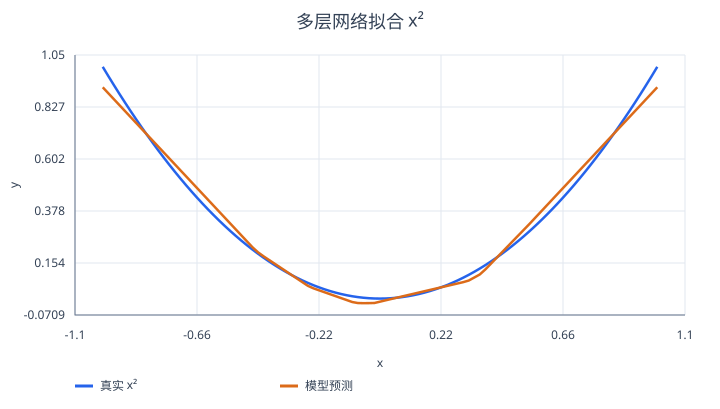

In [66]:
xs = [-1 + 2 * i / 100 for i in range(101)]
y_target = [x * x for x in xs]
y_predicted = [row[0] for row in model([[x] for x in xs], train=False).tolist()]
visualization.Plot(title="多层网络拟合 x²", xlabel="x", ylabel="y").line(xs, y_target, label="真实 x²").line(xs, y_predicted, label="模型预测")


## 3. 保存并加载模型

保存最后训练的平方模型到 `regression.json`，再加载并核对预测。


In [67]:
before = model(samples, train=False).tolist()
model.save("regression.json")
restored = nn.Model().load("regression.json")
after = restored(samples, train=False).tolist()

print("保存前预测:", before)
print("加载后预测:", after)
assert before == after, "加载前后的预测不一致"

保存前预测: [[0.7838651103558396], [0.21018297952442572], [-0.013358387004019423], [0.09748919329505111], [0.6559503735022542]]
加载后预测: [[0.7838651103558396], [0.21018297952442572], [-0.013358387004019423], [0.09748919329505111], [0.6559503735022542]]
